# 05 · Statistical analysis

## Purpose

Test feature-target associations using methods suited to numeric and categorical fields, and report effect sizes and adjusted p-values.

## Method

Compare numeric distributions with two-sided Mann–Whitney U plus rank-biserial effect size and a bootstrap interval for median difference. Compare categorical features with Pearson chi-square and Cramér’s V. Adjust across tests using Benjamini–Hochberg.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

Tests address association, not causality. Small or highly sparse category tables may violate chi-square approximations and should be merged or analyzed with a justified alternative.

## References

SciPy stats: https://docs.scipy.org/doc/scipy/reference/stats.html


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '05 · Statistical analysis')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 05 · Statistical analysis


,feature,test,n_returned,n_kept,summary_returned,summary_kept,effect_size,effect_label,median_difference_ci_low,median_difference_ci_high,p_value,p_adjusted_bh,significant_fdr_0_05
0,product_category,Pearson chi-square,94919,105081,NaN,NaN,0.076458,Cramer's V,NaN,NaN,1.402623e-250,1.542886e-249,True
1,shipping_method,Pearson chi-square,94919,105081,NaN,NaN,0.069611,Cramer's V,NaN,NaN,3.582611e-211,1.970436e-210,True
2,payment_method,Pearson chi-square,94919,105081,NaN,NaN,0.060810,Cramer's V,NaN,NaN,5.501619e-160,2.017260e-159,True
3,device_type,Pearson chi-square,94919,105081,NaN,NaN,0.056712,Cramer's V,NaN,NaN,2.094509e-140,5.759899e-140,True
4,used_coupon,Pearson chi-square,94919,105081,NaN,NaN,0.054950,Cramer's V,NaN,NaN,2.384633e-133,5.246192e-133,True
5,product_price,Mann-Whitney U (two-sided),94919,105081,25.846619,23.262440,0.046222,rank-biserial correlation,1.096929,4.345237,1.729139e-71,3.170087e-71,True
6,num_product_views,Mann-Whitney U (two-sided),94919,105081,12.000000,13.000000,-0.023158,rank-biserial correlation,-1.512500,1.000000,3.233609e-19,5.081386e-19,True
7,session_length_minutes,Mann-Whitney U (two-sided),94919,105081,80.758567,82.240820,-0.020484,rank-biserial correlation,-3.515200,0.503784,2.312879e-15,3.180208e-15,True
8,discount_percent,Mann-Whitney U (two-sided),94919,105081,43.056233,42.825652,0.012981,rank-biserial correlation,-1.109561,1.573153,5.143430e-07,6.286414e-07,True
9,customer_age,Mann-Whitney U (two-sided),94919,105081,58.000000,58.000000,-0.012683,rank-biserial correlation,-2.000000,0.012500,9.276410e-07,1.020405e-06,True


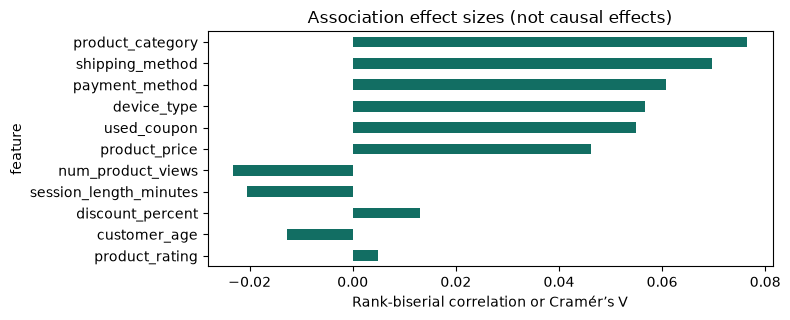

Features passing BH-adjusted p < 0.05: ['product_category', 'shipping_method', 'payment_method', 'device_type', 'used_coupon', 'product_price', 'num_product_views', 'session_length_minutes', 'discount_percent', 'customer_age']


,customer_age,product_price,discount_percent,product_rating,session_length_minutes,num_product_views,used_coupon
customer_age,1.000000,-0.020340,-0.010995,-0.014120,0.013490,-0.018850,0.003167
product_price,-0.020340,1.000000,-0.051324,0.008406,0.009575,-0.039389,0.009644
discount_percent,-0.010995,-0.051324,1.000000,0.037749,0.002875,-0.006398,0.024482
product_rating,-0.014120,0.008406,0.037749,1.000000,-0.003530,0.030819,0.038144
session_length_minutes,0.013490,0.009575,0.002875,-0.003530,1.000000,0.011594,-0.022600
num_product_views,-0.018850,-0.039389,-0.006398,0.030819,0.011594,1.000000,-0.021448
used_coupon,0.003167,0.009644,0.024482,0.038144,-0.022600,-0.021448,1.000000


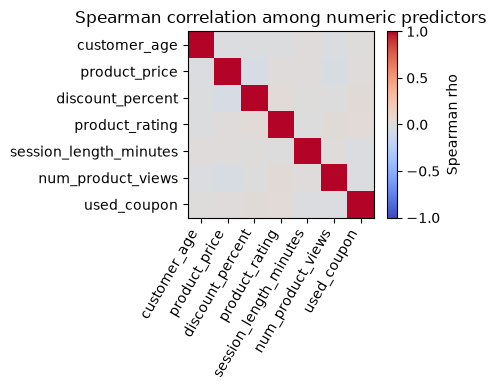

In [2]:
from returnwise.analysis.statistics import association_tests
from returnwise.features import select_features
from returnwise.storage import load_active_dataset
import matplotlib.pyplot as plt

frame, manifest = load_active_dataset()
if frame is None or 'returned' not in frame:
    raise RuntimeError('A labeled active CSV with returned is required for supervised statistical analysis.')
candidate_features = select_features(frame, scenario='pre_shipment')
analysis_frame = frame[candidate_features + ['returned']]
tests = association_tests(analysis_frame)
display(tests)
if not tests.empty:
    plot_data = tests.sort_values('effect_size', key=lambda s: s.abs()).tail(15)
    ax = plot_data.set_index('feature')['effect_size'].plot.barh(figsize=(8, max(3, len(plot_data) * 0.3)), color='#126E63', title='Association effect sizes (not causal effects)')
    ax.set_xlabel('Rank-biserial correlation or Cramér’s V')
    plt.tight_layout()
    plt.show()
    print('Features passing BH-adjusted p < 0.05:', tests.loc[tests['significant_fdr_0_05'], 'feature'].tolist())
    numeric = analysis_frame.select_dtypes(include='number').drop(columns=['returned'], errors='ignore')
    if numeric.shape[1] >= 2:
        correlations = numeric.corr(method='spearman')
        display(correlations)
        fig, ax = plt.subplots(figsize=(max(5, len(correlations) * 0.55), max(4, len(correlations) * 0.45)))
        image = ax.imshow(correlations, cmap='coolwarm', vmin=-1, vmax=1)
        ax.set_xticks(range(len(correlations)), labels=correlations.columns, rotation=60, ha='right')
        ax.set_yticks(range(len(correlations)), labels=correlations.index)
        ax.set_title('Spearman correlation among numeric predictors')
        fig.colorbar(image, ax=ax, label='Spearman rho')
        plt.tight_layout()
        plt.show()
